Imbalanced data occurs when one class has far more samples than others, causing models to favour the majority class and perform poorly on the minority class. This often results in misleading accuracy, especially in critical applications like fraud detection or medical diagnosis.

ML models tend to get biased toward the majority class and predict it more frequently.

Minority class instances may be treated as noise, causing the model to overlook them.

Accuracy becomes misleading because the model performs well only on the dominant class.

Skewed decision boundaries lead to poor generalisation and weak performance on minority class predictions.
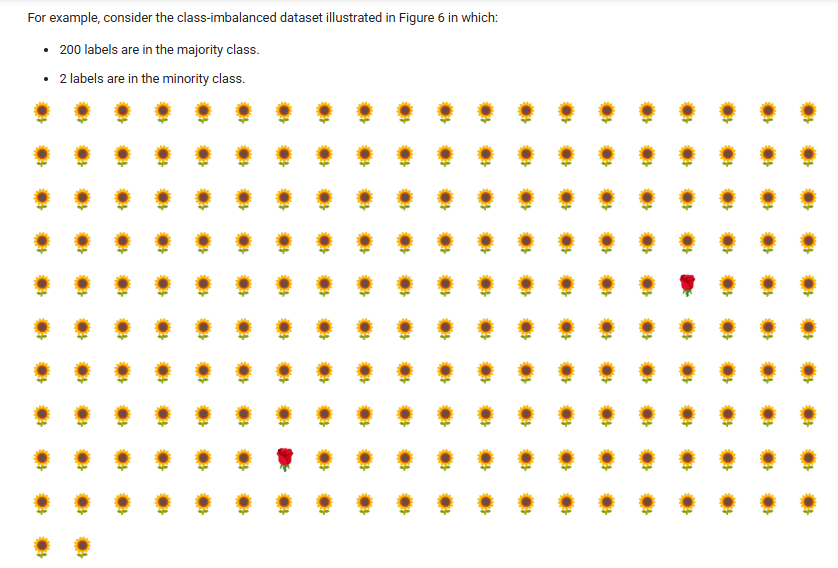

If the batch size is 20, most batches won't contain any examples of the minority class. If the batch size is 100, each batch will contain an average of only one minority class example, which is insufficient for proper training. Even a much larger batch size will still yield such an imbalanced proportion that the model might not train properly.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/student_cleaned.csv")

In [ ]:
df.head()

,Student_ID,Name,Gender,Age,Department,Semester,CGPA,Attendance,Placement_Status,City,Hostel,Family_Income,Backlogs,Study_Hours,Internship
0,1001,Simran Sharma,Female,19.0,ECE,3,8.67,94.0,Placed,Ludhiana,No,266653,0,1.7,Yes
1,1002,Muskan Arora,Male,22.0,ECE,7,6.45,97.0,Not Placed,Jalandhar,Yes,534829,3,3.4,Yes
2,1003,Rohit Patel,Male,18.0,ME,2,7.04,82.0,Not Placed,Jalandhar,Yes,1163483,4,1.9,No
3,1004,Rahul Joshi,Female,24.0,EEE,6,7.98,64.0,Not Placed,Delhi,Yes,806890,0,7.0,Yes
4,1005,Riya Gupta,Female,23.0,IT,3,7.09,73.0,Not Placed,Jalandhar,Yes,1477440,1,4.7,Yes


In [ ]:
df["Placement_Status"] = df["Placement_Status"].str.title()
df["Placement_Status"].value_counts()

,count
Placement_Status,
Not Placed,317
Placed,173


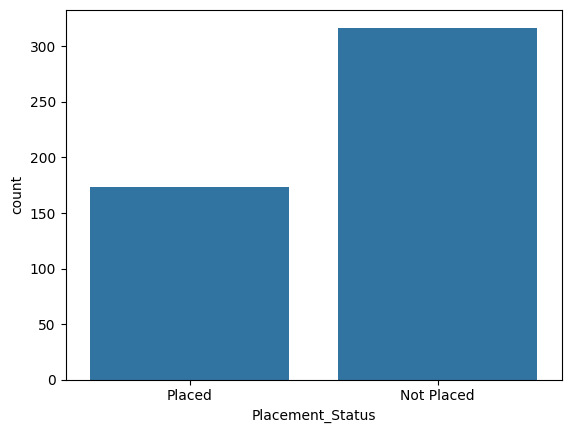

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.countplot(
    data=df,
    x="Placement_Status"
)

plt.show()

Out of 490 students, 35% are placed and 75% are not placed.

The classes are imbalanced

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Encode the target
le = LabelEncoder()
df["Placement_Status"] = le.fit_transform(df["Placement_Status"])

# One-hot encode categorical features
df = pd.get_dummies(df, drop_first=True)

X = df.drop("Placement_Status", axis=1)
y = df["Placement_Status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

In [ ]:
from collections import Counter
print("Original:", Counter(y_train))

Original: Counter({0: 254, 1: 138})


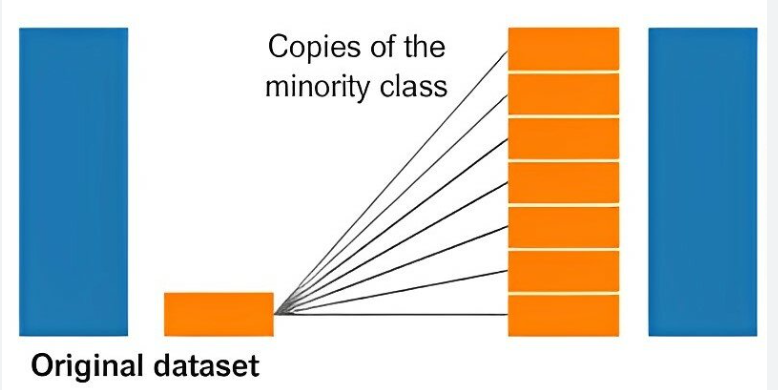

Random oversampling is a technique used in machine learning to balance imbalanced datasets. It works by randomly duplicating existing examples from the minority class—often with replacement—until the class distribution is equal to the majority class.

In [ ]:
# Random Oversampling
from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(random_state=42)
X_ros, y_ros = ros.fit_resample(X_train, y_train)
print(Counter(y_ros))

Counter({1: 254, 0: 254})


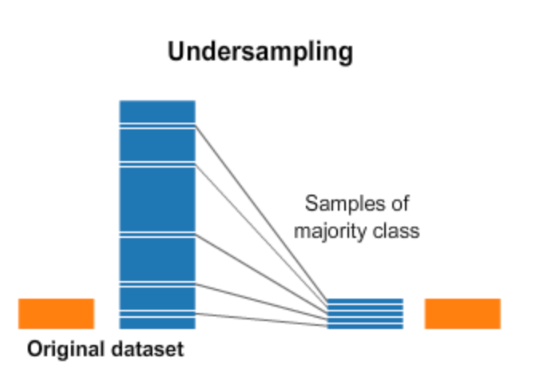

Random undersampling is a technique used in machine learning to balance imbalanced datasets by randomly deleting examples from the majority class. While it speeds up training time, it risks discarding potentially valuable information needed for the model to learn accurately.

In [ ]:
# Random Undersampling
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=42)
X_rus, y_rus = rus.fit_resample(X_train, y_train)
print(Counter(y_rus))

Counter({0: 138, 1: 138})


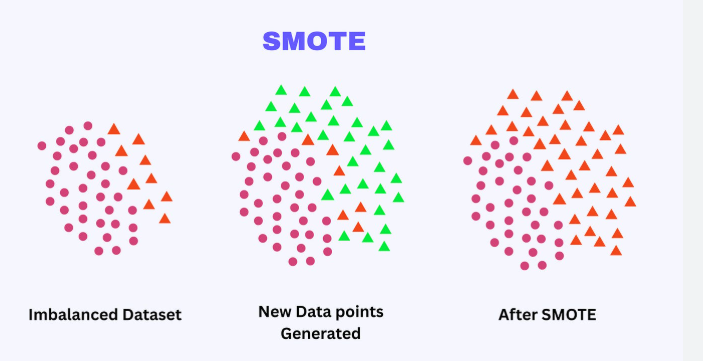

SMOTE (Synthetic Minority Over-sampling Technique) is an algorithm used to fix class imbalance in machine learning datasets. Instead of duplicating existing minority data, which leads to overfitting, SMOTE creates new, realistic synthetic data points by calculating distances between existing minority examples and interpolating new points along the lines connecting them.

In [ ]:
# SMOTE
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_sm, y_sm = smote.fit_resample(X_train, y_train)
print(Counter(y_sm))

Counter({1: 254, 0: 254})


 It is a machine learning data-cleaning method used to handle imbalanced datasets. It identifies pairs of data points from different classes (e.g., a majority class and a minority class) that are the nearest neighbors to each other, and removes the majority class point to create a clearer separation between classes.

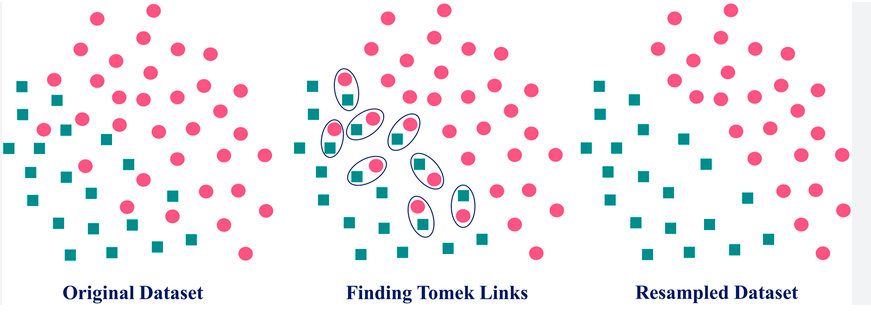

In [ ]:
# TOMEK LINKS
from imblearn.under_sampling import TomekLinks

tl = TomekLinks()
X_tl, y_tl = tl.fit_resample(X_train, y_train)
print(Counter(y_tl))

Counter({0: 198, 1: 138})


ADASYN (Adaptive Synthetic) is a machine learning technique used to handle imbalanced datasets by generating synthetic samples for the minority class. It differs from basic oversampling by focusing on the "harder-to-learn" examples, shifting the model's decision boundary to better classify difficult data points.

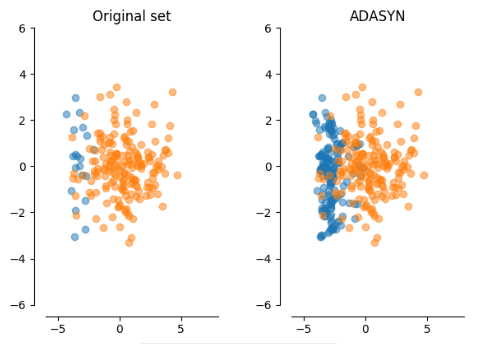

In [ ]:
# ADASYN
from imblearn.over_sampling import ADASYN

ada = ADASYN(random_state=42)
X_ada, y_ada = ada.fit_resample(X_train, y_train)
print(Counter(y_ada))

Counter({1: 266, 0: 254})


Standard SMOTE can sometimes create synthetic points that bleed too deeply into the majority class territory, causing noise. SMOTETomek runs SMOTE first, then drops overlapping "Tomek link" point pairs to clarify class borders.

In simple words, It combines SMOTE (to create synthetic data for the minority class) and Tomek Links (to clean up noisy or overlapping data points between classes)

In [ ]:
# SMOTE + TOMEK Links
from imblearn.combine import SMOTETomek

smt = SMOTETomek(random_state=42)
X_smt, y_smt = smt.fit_resample(X_train, y_train)
print(Counter(y_smt))

Counter({0: 192, 1: 192})
